**Loading the Libraries**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import DBSCAN
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

reading the data from the CSV 

also plotting data and the original ground outlier in the dataset

Dataset loaded: 10000 rows, 30 numeric features.
Ground-Truth Outliers: 492 rows (4.92%)


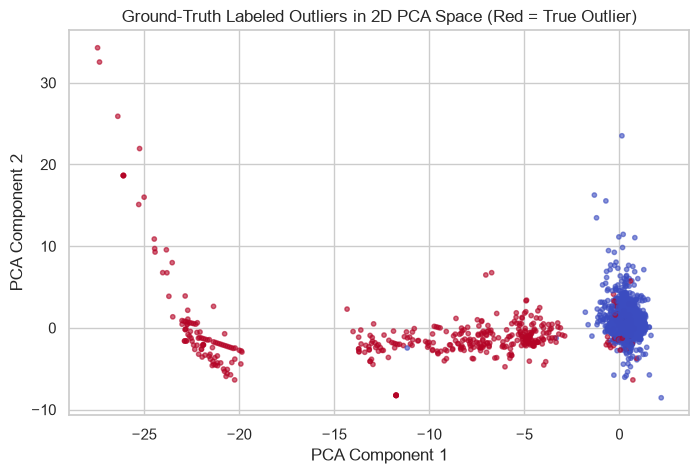

In [2]:
csv_path = "./data/creditcard.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"'{csv_path}' not found. Run 'uv run python download_dataset.py' first."
    )

# Load full dataset
raw_df = pd.read_csv(csv_path)

# Keep all 492 labeled fraud outliers (Class == 1) and 9,508 normal rows (Class == 0)
# Total = 10,000 rows (4.92% true outliers) so density/distance matrices fit comfortably in RAM
frauds = raw_df[raw_df["Class"] == 1]
normals = raw_df[raw_df["Class"] == 0].sample(n=9508, random_state=42)
df = pd.concat([normals, frauds]).sample(frac=1, random_state=42).reset_index(drop=True)

# Separate numeric features (30 columns: Time, V1-V28, Amount) and ground-truth outlier label (Class)
X = df.drop(columns=["Class"]).copy()
y_true = df["Class"].astype(int).copy()  # 1 = True Outlier (Fraud), 0 = Normal

# Standardize all 30 numeric features (mean = 0, std = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Compute 2D PCA projection for plotting
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Store true outlier ratio for configuring algorithms
contamination_rate = float(y_true.mean())

# DataFrame to store binary predictions (1 = Outlier, 0 = Inlier) for each method
outliers_df = pd.DataFrame(index=df.index)

print(f"Dataset loaded: {X.shape[0]} rows, {X.shape[1]} numeric features.")
print(f"Ground-Truth Outliers: {y_true.sum()} rows ({contamination_rate * 100:.2f}%)")

# Visualize Ground-Truth Outliers in PCA Space
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="coolwarm", s=10, alpha=0.6)
plt.title("Ground-Truth Labeled Outliers in 2D PCA Space (Red = True Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Mahalanobis Threshold (Chi2, p=0.01): 50.89
Mahalanobis Outliers Detected: 763 (7.63%)
F1-Score vs Ground Truth: 0.4430


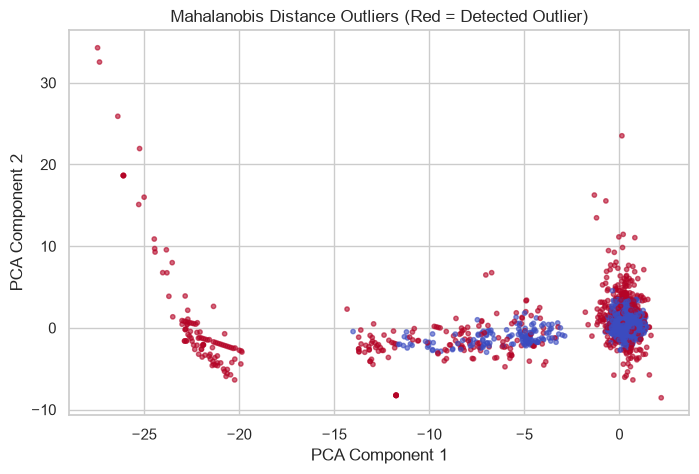

In [3]:
# Compute mean vector and inverse covariance matrix
mean_vec = np.mean(X_scaled, axis=0)
cov_matrix = np.cov(X_scaled, rowvar=False)
inv_cov_matrix = np.linalg.pinv(cov_matrix)

# Compute squared Mahalanobis distance for every sample
diff = X_scaled - mean_vec
md_squared = np.sum(np.dot(diff, inv_cov_matrix) * diff, axis=1)

# Chi-Square threshold at 99% confidence (p = 0.01) with 30 degrees of freedom
dof = X_scaled.shape[1]
threshold_md = chi2.ppf(0.99, dof)

outliers_df["Mahalanobis"] = (md_squared > threshold_md).astype(int)

n_md = outliers_df["Mahalanobis"].sum()
print(f"Mahalanobis Threshold (Chi2, p=0.01): {threshold_md:.2f}")
print(f"Mahalanobis Outliers Detected: {n_md} ({n_md / len(df) * 100:.2f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['Mahalanobis']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Mahalanobis"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Mahalanobis Distance Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Isolation Forest Outliers Detected: 492 (4.92%)
F1-Score vs Ground Truth: 0.6220


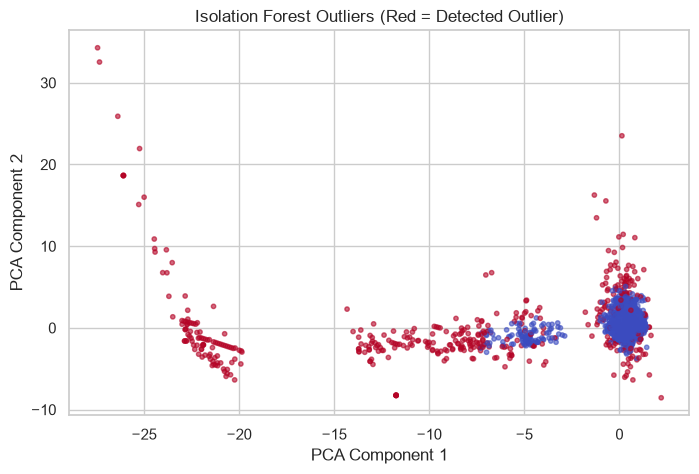

In [4]:
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=contamination_rate,
    random_state=42,
    n_jobs=-1
)

# fit_predict returns -1 for outliers and 1 for inliers
iso_preds = iso_forest.fit_predict(X_scaled)
outliers_df["Isolation_Forest"] = (iso_preds == -1).astype(int)

n_iso = outliers_df["Isolation_Forest"].sum()
print(f"Isolation Forest Outliers Detected: {n_iso} ({n_iso / len(df) * 100:.2f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['Isolation_Forest']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Isolation_Forest"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Isolation Forest Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

LOF Outliers Detected: 492 (4.92%)
F1-Score vs Ground Truth: 0.1098


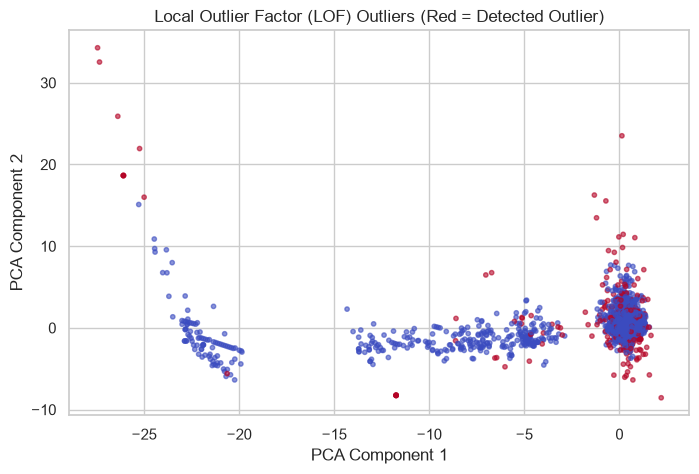

In [5]:
lof = LocalOutlierFactor(
    n_neighbors=35,
    contamination=contamination_rate,
    n_jobs=-1
)

# fit_predict returns -1 for outliers and 1 for inliers
lof_preds = lof.fit_predict(X_scaled)
outliers_df["LOF"] = (lof_preds == -1).astype(int)

n_lof = outliers_df["LOF"].sum()
print(f"LOF Outliers Detected: {n_lof} ({n_lof / len(df) * 100:.2f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['LOF']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["LOF"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Local Outlier Factor (LOF) Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

DBSCAN Clusters Found: 3
DBSCAN Outliers Detected: 529 (5.29%)
F1-Score vs Ground Truth: 0.4721


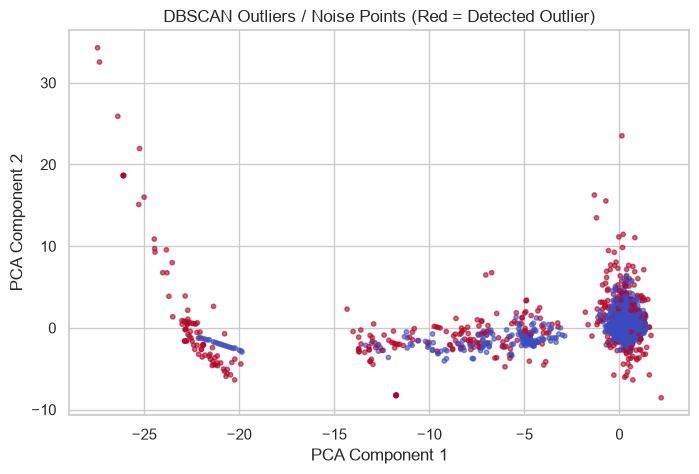

In [6]:
dbscan = DBSCAN(eps=4.5, min_samples=10, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X_scaled)

# In DBSCAN, label -1 indicates noise/outliers
outliers_df["DBSCAN"] = (dbscan_labels == -1).astype(int)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_db = outliers_df["DBSCAN"].sum()
print(f"DBSCAN Clusters Found: {n_clusters}")
print(f"DBSCAN Outliers Detected: {n_db} ({n_db / len(df) * 100:.2f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['DBSCAN']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["DBSCAN"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("DBSCAN Outliers / Noise Points (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

One-Class SVM Outliers Detected: 493 (4.93%)
F1-Score vs Ground Truth: 0.4305


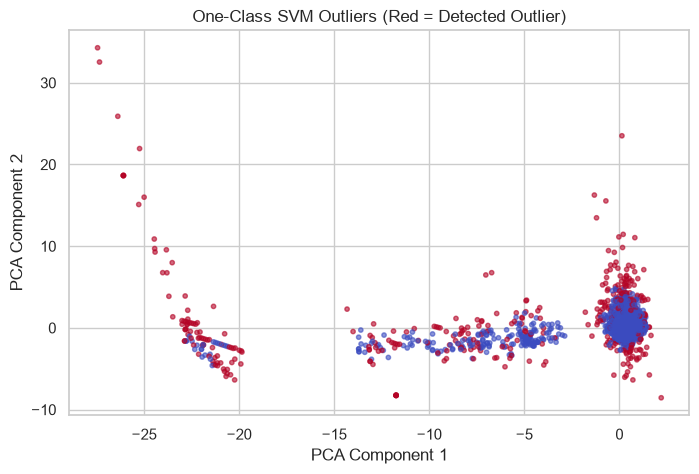

In [7]:
oc_svm = OneClassSVM(kernel="rbf", gamma="scale", nu=contamination_rate)

svm_preds = oc_svm.fit_predict(X_scaled)
outliers_df["OneClass_SVM"] = (svm_preds == -1).astype(int)

n_svm = outliers_df["OneClass_SVM"].sum()
print(f"One-Class SVM Outliers Detected: {n_svm} ({n_svm / len(df) * 100:.2f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['OneClass_SVM']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["OneClass_SVM"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("One-Class SVM Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Z-Score Outliers Detected: 640 (6.40%)
F1-Score vs Ground Truth: 0.5177


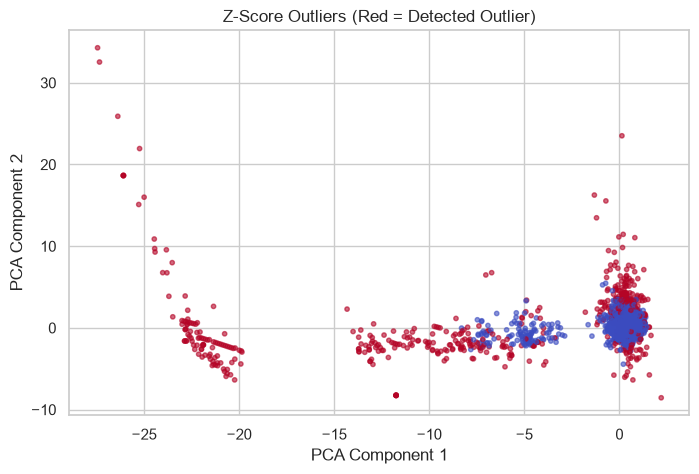

In [8]:
z_threshold = 4.0
outliers_df["Z_Score"] = (np.abs(X_scaled) > z_threshold).any(axis=1).astype(int)

n_z = outliers_df["Z_Score"].sum()
print(f"Z-Score Outliers Detected: {n_z} ({n_z / len(df) * 100:.2f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['Z_Score']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Z_Score"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Z-Score Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

=== QUANTITATIVE PERFORMANCE EVALUATION (AGAINST GROUND TRUTH) ===


,Detected_Outliers,True_Positives (TP),False_Positives (FP),False_Negatives (FN),Accuracy,Precision,Recall,F1-Score,ROC-AUC
Method,,,,,,,,,
Isolation_Forest,492,306,186,186,0.9628,0.6220,0.6220,0.6220,0.8012
Z_Score,640,293,347,199,0.9454,0.4578,0.5955,0.5177,0.7795
DBSCAN,529,241,288,251,0.9461,0.4556,0.4898,0.4721,0.7298
Mahalanobis,763,278,485,214,0.9301,0.3644,0.5650,0.4430,0.7570
OneClass_SVM,493,212,281,280,0.9439,0.4300,0.4309,0.4305,0.7007
LOF,492,54,438,438,0.9124,0.1098,0.1098,0.1098,0.5318


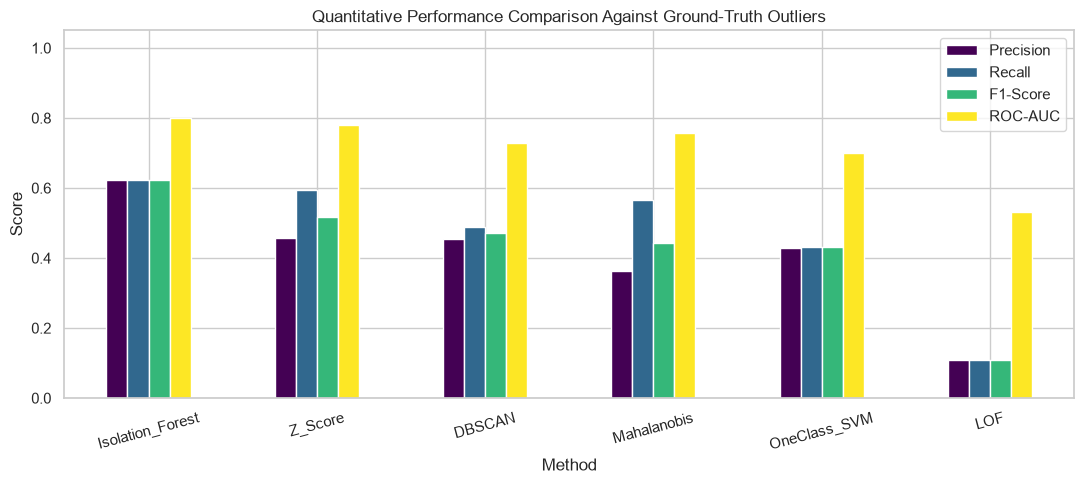

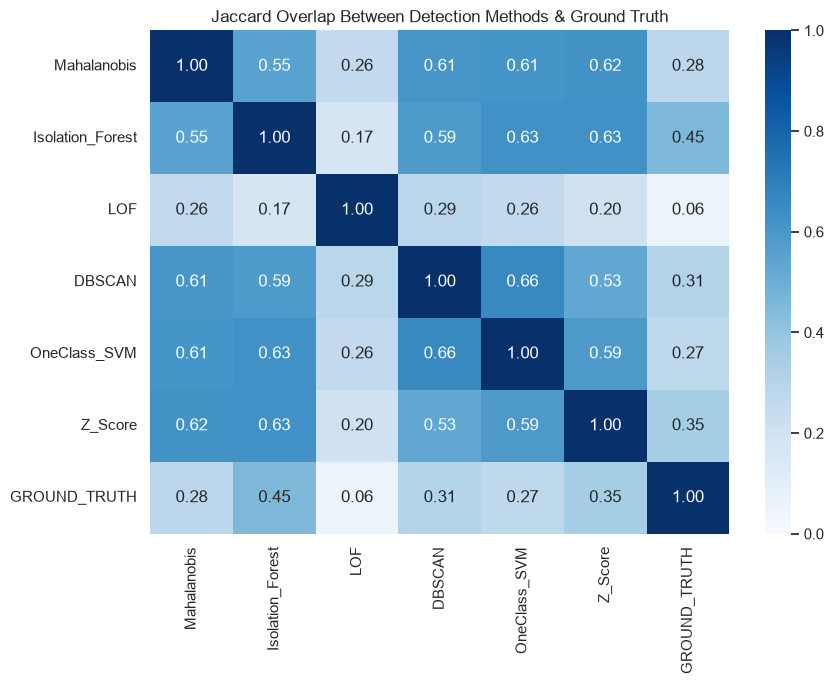

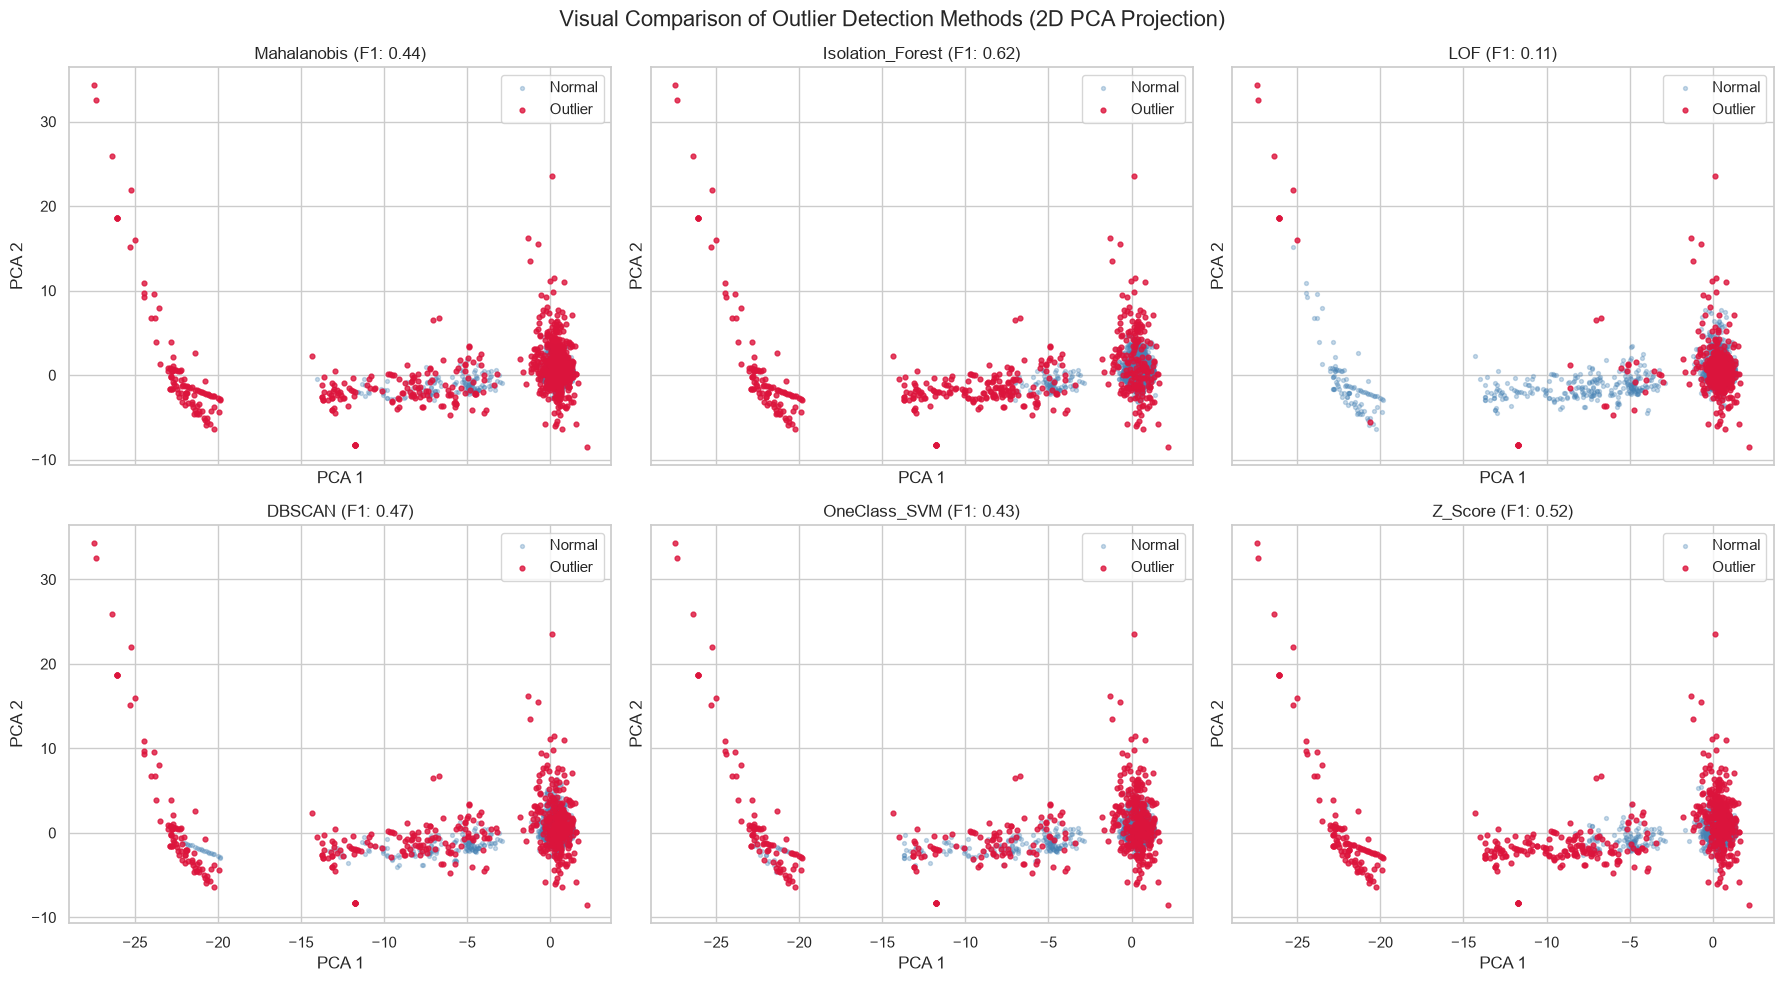

In [9]:
# 1. Quantitative Performance Against Real Ground-Truth Labels (y_true)
eval_rows = []
for method in outliers_df.columns:
    y_pred = outliers_df[method]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    eval_rows.append({
        "Method": method,
        "Detected_Outliers": int(y_pred.sum()),
        "True_Positives (TP)": int(tp),
        "False_Positives (FP)": int(fp),
        "False_Negatives (FN)": int(fn),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_pred)
    })

eval_df = pd.DataFrame(eval_rows).set_index("Method").sort_values(by="F1-Score", ascending=False)
print("=== QUANTITATIVE PERFORMANCE EVALUATION (AGAINST GROUND TRUTH) ===")
display(eval_df.round(4))

# 2. Bar Chart Comparing Precision, Recall, F1-Score, and ROC-AUC
eval_df[["Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), rot=15, colormap="viridis"
)
plt.title("Quantitative Performance Comparison Against Ground-Truth Outliers")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# 3. Pairwise Agreement Heatmap (Jaccard Similarity Including Ground Truth)
compare_df = outliers_df.copy()
compare_df["GROUND_TRUTH"] = y_true
cols = compare_df.columns
jaccard = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        inter = np.logical_and(compare_df[c1], compare_df[c2]).sum()
        union = np.logical_or(compare_df[c1], compare_df[c2]).sum()
        jaccard.loc[c1, c2] = inter / union if union > 0 else 0.0

plt.figure(figsize=(9, 7))
sns.heatmap(jaccard, annot=True, cmap="Blues", fmt=".2f", vmin=0, vmax=1)
plt.title("Jaccard Overlap Between Detection Methods & Ground Truth")
plt.tight_layout()
plt.show()

# 4. Side-by-Side 2x3 Visual Comparison in PCA Space
methods = outliers_df.columns
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

for idx, method in enumerate(methods):
    ax = axes[idx]
    inliers = outliers_df[method] == 0
    outliers = outliers_df[method] == 1

    ax.scatter(X_pca[inliers, 0], X_pca[inliers, 1], c="steelblue", s=8, alpha=0.3, label="Normal")
    ax.scatter(X_pca[outliers, 0], X_pca[outliers, 1], c="crimson", s=12, alpha=0.8, label="Outlier")
    ax.set_title(f"{method} (F1: {eval_df.loc[method, 'F1-Score']:.2f})")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend(loc="upper right")

plt.suptitle("Visual Comparison of Outlier Detection Methods (2D PCA Projection)", fontsize=16)
plt.tight_layout()
plt.show()